## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maleah Caboteja

**Date:** Oct 15

2. When the noise increased from 0.125 to 2.0 the clusters disperese and the spaces between the points increase. With the lower noise levels the groups are closer and more packed so we can see the seperation between the different cluster groups. Once the noise gets louder we find it harder to see the distinct groups. 
3. The more the noise level increases the sum of the distances between them increases. This is because the data points disperse further from their center. The elbow on the scree plot is shown at k=3. This highlights the number of clusters. When the noise goes from 1.0-2.0 the point starts to flatten the curve and makes i harder to choose a k.
1. The elbow on the group is the turning point a k=3. We go from 1-3 clusters which cuts the intertia down because the data has 3 groups, so if we added more clusters it doesn't help becaues we would be splitting up the groups. 

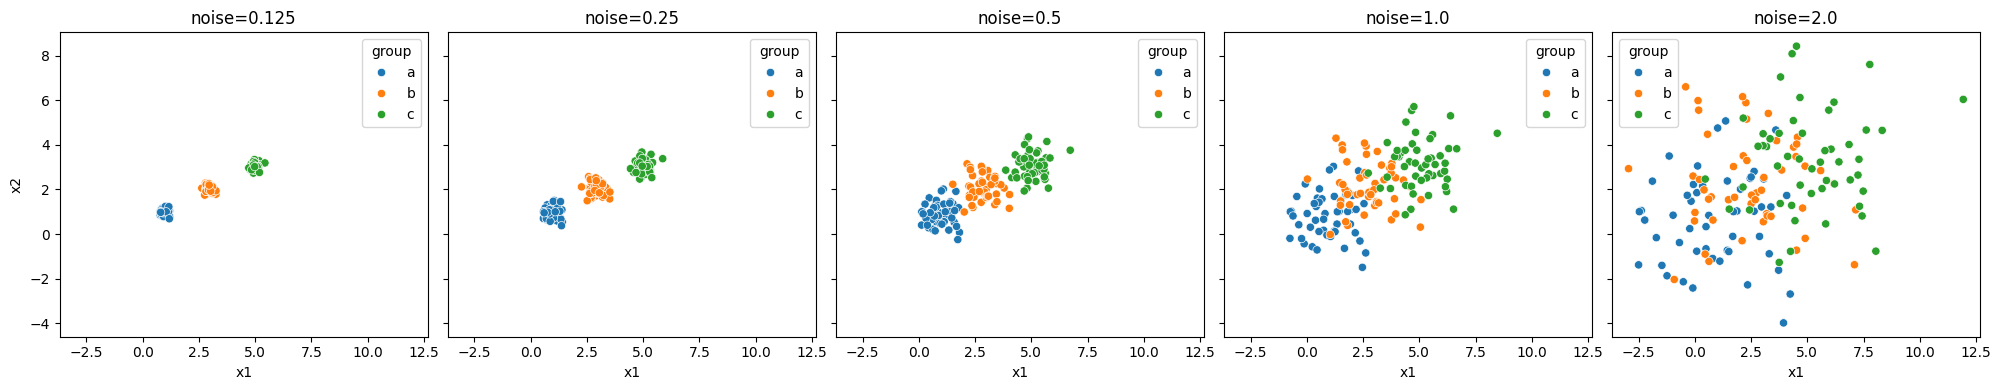

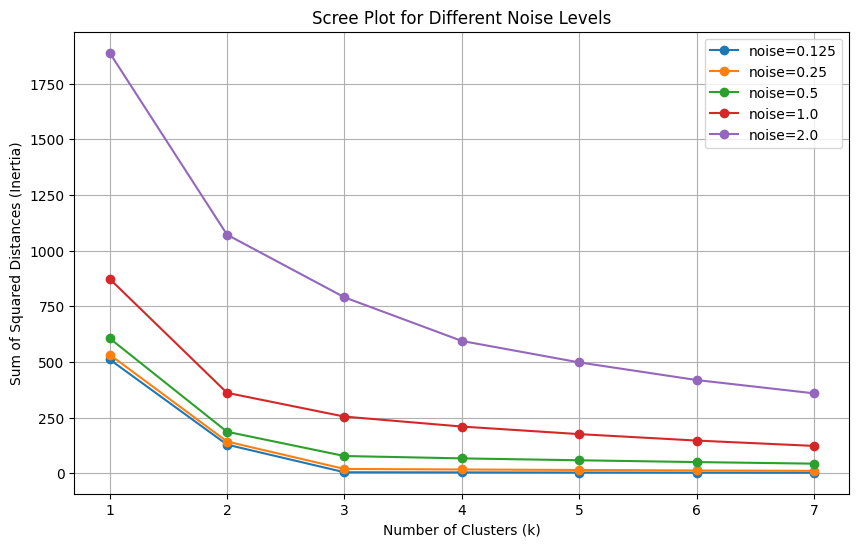

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {'noise=0.125': df0_125, 'noise=0.25': df0_25, 'noise=0.5': df0_5, 'noise=1.0': df1_0, 'noise=2.0': df2_0}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, sharey=True)
for ax, (title, df) in zip(axes, datasets.items()):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
plt.tight_layout()

plt.show()

range_k = range(1,8)
scree = {}

for label, df in datasets.items():
    X = df[['x1','x2']]
    cluster_sum = []
    for k in range_k:
        k_means = KMeans(n_clusters=k, random_state=100, n_init=10)
        k_means.fit(X)
        cluster_sum.append(k_means.inertia_)
    scree[label] = cluster_sum

plt.figure(figsize=(10, 6))
for label, cluster_sum in scree.items():
    plt.plot(range_k, cluster_sum, marker='o', label=label)

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Sum of Squared Distances (Inertia)')
plt.title('Scree Plot for Different Noise Levels')
plt.legend()
plt.grid(True)
plt.show()



For reference, I named the variables based on the questions they correspond to (pt2-4)

1. Yes I did more cleaning past that i formatted the numeric column in case there were any strings/commas in it and converted them so that kmeans would be properly calculated.
2. In the scree plot where is an elbow at k=3 and following that there is a decrease in intertia. Cluster 0 has 126 low spending countries, cluster 1 has 21 high per capita spenders, and 2 as one outlier. The US is in cluster 2 and is influenced by the 778 billion budget and the 2351 per capita spending. The spending is right-skewed because kmeans isolates the US as an outlier and forces the 85% of countries into a seperate group (148 total countries, 126 in cluster 0, 126/148 = ~85).
3. These results vary because it normalizes the country's size and distributes the nations in a more balanced way in their groups. There are now 99 in cluster 1, 39 in 0, and 10 in 2. The US in part/question 2 was isolated because we used USD scale but now in this part it is the measurement of the percentages in normalized by the country size so it's not like one nation overpowers one cluster. So we can now see the balance of groups baed on their military spending since the countries better normalized in size and distribution instead of the US being isolated in part 2 (used a line of code to see the exact cluster the US is in in both parts).
4. There are no single outliers for this part because we combined the four numeric variables to prevent the US from being its own cluster like in 2. Part 3 focused ont the percentages distributed, while part 4 looks into the smaller military focused countries from the higher expenditure countries. This way we can see the countries in different clusters that organize them by lower spending (0), balanced spending (3), regional spenders (2), and global power (1) (wrote extra lines to examine these).
5. Yes it did, we were able to look at the spending habits towards defense by looking into the different countries under certain categories of spending and look at skewed outliers.

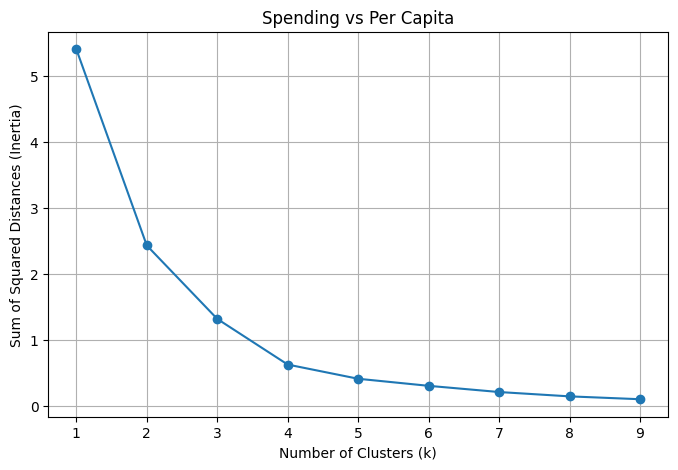

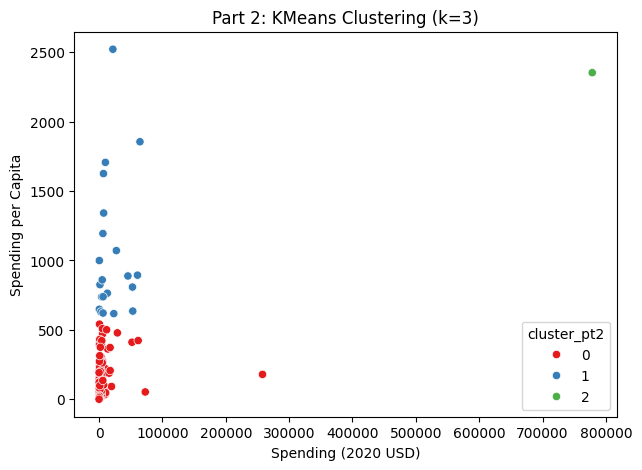

United States Pt2 Cluster: [2]
            Spending (2020 USD)                                              \
                          count           mean           std            min   
cluster_pt2                                                                   
0                         126.0    5943.346303  24858.961064       8.622460   
1                          21.0   19975.991473  21749.736747     405.790494   
2                           1.0  778397.200000           NaN  778397.200000   

                                                                         \
                       25%            50%            75%            max   
cluster_pt2                                                               
0               162.761743     580.758315    3225.333414  257973.429834   
1              4980.428135    7269.880030   27300.894701   64558.400000   
2            778397.200000  778397.200000  778397.200000  778397.200000   

            Spending per Capita            

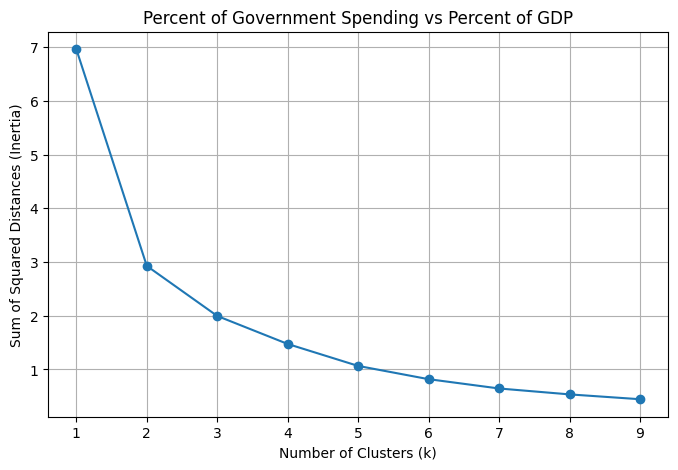

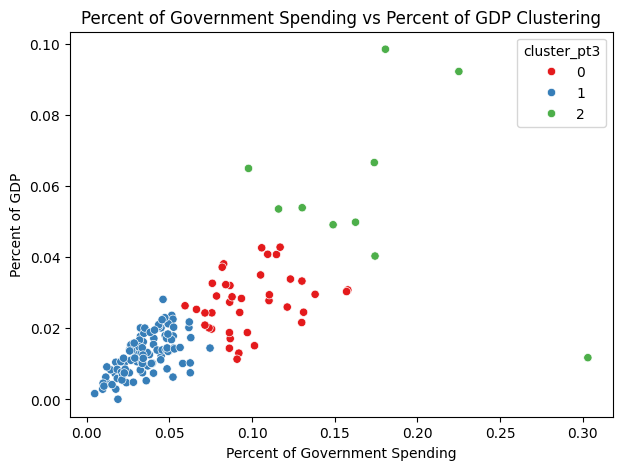

            Percent of Government Spending                                \
                                     count      mean       std       min   
cluster_pt3                                                                
0                                     39.0  0.098683  0.024125  0.059520   
1                                     99.0  0.035777  0.014549  0.004896   
2                                     10.0  0.171289  0.058725  0.097882   

                                                    Percent of GDP            \
                  25%       50%       75%       max          count      mean   
cluster_pt3                                                                    
0            0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1            0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2            0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                              

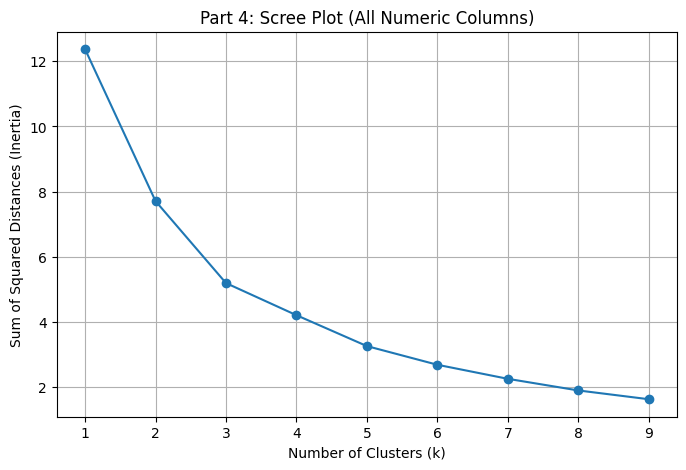

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      26.0   15330.618681   18923.469359   405.790494   
3                      30.0    9073.543709   18135.032885   163.926877   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2        3176.345598   5857.060906  21818.934764   60675.039625   
3         522.737081   1663.090134   8646.648849   72937.064048   

        Spe

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# 1 loading the csv and cleaning the data 
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df2020 = df[df['Year'] == 2020].dropna().copy()

columns_nums = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

for col in columns_nums:
    df2020[col] = pd.to_numeric(df2020[col].astype(str).str.replace(',', ''), errors='coerce')

df2020 = df2020.dropna(subset=columns_nums)

def scree_plot(data_scaled, title="Scree Plot"):
    range_k = range(1, 10)
    cluster_sum = []
    for k in range_k:
        k_means = KMeans(n_clusters=k, random_state=42, n_init=10)
        k_means.fit(data_scaled)
        cluster_sum.append(k_means.inertia_)
    
    plt.figure(figsize=(8, 5))
    plt.plot(range_k, cluster_sum, marker='o')
    plt.title(title)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Sum of Squared Distances (Inertia)')
    plt.grid(True)
    plt.show()

scale = MinMaxScaler()

# 2 max-min normalize spending and spending per capita
cols2 = ['Spending (2020 USD)', 'Spending per Capita']
scaled2 = scale.fit_transform(df2020[cols2])
scree_plot(scaled2, "Spending vs Per Capita")
p2_k = 3
kmeans2 = KMeans(n_clusters=p2_k, random_state=42, n_init=10)
df2020['cluster_pt2'] = kmeans2.fit_predict(scaled2)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df2020, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster_pt2', palette='Set1')
plt.title(f'Part 2: KMeans Clustering (k={p2_k})')
plt.show()

# I added to look into for anlysis
cluster_pt2 = df2020[df2020['Country'] == 'United States of America']['cluster_pt2'].values
print(f"United States Pt2 Cluster: {cluster_pt2}")
print(df2020.groupby('cluster_pt2')[cols2].describe())

# 3 percent of gov spending and percent gdp
cols3 = ['Percent of Government Spending', 'Percent of GDP']
scaled3 = scale.fit_transform(df2020[cols3])
scree_plot(scaled3, "Percent of Government Spending vs Percent of GDP")
p3_k = 3
kmeans3 = KMeans(n_clusters=p2_k, random_state=42, n_init=10)
df2020['cluster_pt3'] = kmeans3.fit_predict(scaled3)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df2020, x='Percent of Government Spending', y='Percent of GDP', hue='cluster_pt3', palette='Set1')
plt.title('Percent of Government Spending vs Percent of GDP Clustering')
plt.show()

print(df2020.groupby('cluster_pt3')[cols3].describe())

# I also added to talk about in answer
cluster_pt3 = df2020[df2020['Country'] == 'United States of America']['cluster_pt3'].values
print(f"United States Pt3 Cluster: {cluster_pt3}")

# 4 all numeric columns

scaled4 = scale.fit_transform(df2020[columns_nums])
scree_plot(scaled4, "Part 4: Scree Plot (All Numeric Columns)")
part4 = 4
kmeans4 = KMeans(n_clusters=part4, random_state=42, n_init=10)
df2020['cluster'] = kmeans4.fit_predict(scaled4)
print(df2020.groupby('cluster')[columns_nums].describe())

c0 = df2020[df2020['cluster'] == 0]['Country'].tolist()
c1 = df2020[df2020['cluster'] == 1]['Country'].tolist()
c2 = df2020[df2020['cluster'] == 2]['Country'].tolist()
c3 = df2020[df2020['cluster'] == 3]['Country'].tolist()

# for analysis purposes I wrote this to look into the countries in each

print(f"cluster 0 Countries: {c0}")
print(f"cluster 1 Countries: {c1}")
print(f"cluster 2 Countries: {c2}") 
print(f"cluster 3 Countries: {c3}")


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]